# Milestone 2 - Week 1: Data and Baseline Foundation
## Pre-labeled Hugging Face maze-curriculum dataset - revised and completed version (v2)

This notebook is the **Week-1 deliverable of Milestone 2**. It is built on
**`selimaktas/maze-curriculum-dataset`** (Hugging Face, MIT license, 60k ASCII mazes with
*provided* solutions). **No BFS and no other search is used anywhere in the data or the
evaluation pipeline**: label masks are replayed from the provided solution strings, and
predictions are checked by deterministic path tracing (Section 4).

The notebook is **self-contained** (Colab or local, no repository files needed). Dependencies:
`torch`, `numpy`, `matplotlib`, `datasets`. Device is chosen automatically (CUDA > Apple MPS > CPU).

### Week-1 task checklist

| Priority | Task | Deliverable | Where |
|---|---|---|---|
| P0 | Dataset selection | Dataset documented: format, solution labels, sizes of all 3 levels | Section 1 |
| P0 | Data adapter | `MazeDataset` (3-channel tensors + solution masks) + `DataLoader` | Section 2 |
| P0 | Dataset validation | Start/goal, path connectivity, wall collisions, perfect-maze check, duplicates (exact + symmetric), split leakage - on **all 60k** samples | Section 3 |
| P0 | Evaluation | Strict maze-solving metric (exact single legal S-to-G path) + self-tests | Section 4 |
| P0 | First baseline | `RecurrentCNN` trained on easy (5x5) mazes, predictions and results | Sections 5-7 |
| P1 | Simple CNN | Non-recurrent `PlainCNN` baseline | Section 8 |
| - | Comparison | 3-seed comparison table, side-by-side visual comparison | Section 9 |
| - | Wrap-up | Hyperparameters, numerical summary, limitations, Week-2 hand-off | Section 10 |

### Revision notes - what the review of v1 found and what changed

| # | Issue in v1 | Why it matters | Fix in v2 |
|---|---|---|---|
| 1 | The "strict" metric only checked that a shortest S-to-G route *exists inside* the predicted cells. Any over-prediction passed - even predicting **every walkable cell** scored strict = 1 (v1's own self-test asserted this). | v1's headline "strict 0.799 / 0.695" was really a *path-coverage* (connectivity-style) score; the true exact-solve rate was 0.7% / 0.0%. | `strict` now requires the prediction to be **exactly one simple, legal S-to-G path with no extra cells and optimal length**. The old quantity is kept as `covers_path` and shown side by side. |
| 2 | Models trained 6 epochs (training loss still falling). | Baselines were far from converged. | 40 epochs, cosine LR decay, gradient clipping, best-on-validation checkpointing. |
| 3 | `replay_solution` accepted walks that passed through `E` and kept going ("covers E" instead of "ends on E"); revisits were not detected. | Validation could miss malformed solutions. | Replay returns the end cell and a revisit flag; validation requires *ends exactly on E* and a simple walk. |
| 4 | Validation covered only the size-5 pool and only 4 checks; "path connectivity" and "unique solution" were assumed from the dataset card. | The deliverable asks for verified samples. | 10 checks on **all 60,000** mazes, including a search-free union-find **perfect-maze (spanning-tree) proof**, lattice/border checks, and symmetry-aware duplicate detection; train/val/test leakage is asserted to be zero. |
| 5 | Plain `TensorDataset`; per-sample (slow) evaluation; NumPy deprecation warnings from mixing torch tensors into NumPy ops; hard-coded CPU. | Deliverable asks for a working Dataset/DataLoader. | `MazeDataset` class, batched evaluation, clean NumPy inputs, automatic device. |
| 6 | Single seed, only first-4 examples shown, no learning curves, no failure analysis. | Results and visual comparisons were thin. | 3 seeds (mean +/- std), learning curves, solved vs failed galleries with failure reasons, accuracy by path length, side-by-side model comparison, results saved to JSON. |
| 7 | `detour_len` averaged a `-1` sentinel together with real values. | Meaningless average (printed -0.18). | Replaced by explicit `extra_cells` / `missed_cells` counts. |

In [15]:
# ============================ 0. Setup ============================
%matplotlib inline
import json
import subprocess
import sys
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

try:  # 'datasets' (Hugging Face) is auto-installed if missing (e.g. fresh Colab)
    import datasets
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets"], check=False)
    import datasets

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")


def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)


SEED = 0
set_seed(SEED)
RESULTS = Path.cwd() / "week1_results"
RESULTS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10})

print("python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", np.__version__,
      "| datasets", datasets.__version__, "| device:", DEVICE)

python 3.13.18 | torch 2.14.1+cpu | numpy 2.4.6 | datasets 4.8.5 | device: cpu


## 1) Dataset selection (P0)

**Chosen dataset: `selimaktas/maze-curriculum-dataset`** (Hugging Face, MIT license).

Why this dataset:

- an **existing, pre-labeled** dataset: solutions are *provided* as move strings, so labels are
  not produced by our own solver;
- **60,000 mazes with a built-in curriculum**: `grid_size` 5 (25k), 7 (20k), 9 (15k) navigable
  cells per side. Week 1 trains on the easy level (5), the harder levels (`grid_size` 7 and 9) are the difficulty axis
  for Week-2 / Week-3 experiments;
- per the dataset card the mazes are generated with Wilson's algorithm, i.e. **perfect mazes**
  (spanning trees) with exactly one S-to-E path - labels are unambiguous. *We do not take this on
  trust: Section 3 proves it for every sample;*
- small (about 5 MB parquet) and re-downloadable - fully reproducible.

| field | type | content |
|---|---|---|
| `prompt` | string | LLM instruction text (unused - we work on tensors) |
| `maze` | string | ASCII maze: `#` wall, space free, `S` start, `E` end |
| `solution` | string | provided solution as moves `N`/`S`/`E`/`W` |
| `grid_size` | int | navigable cells per side `N`; the ASCII grid is `(2N+1) x (2N+1)` |

Geometry: navigable cells sit at odd ASCII coordinates, wall "pillars" at even-even coordinates,
and the cells in between are either walls or open passages. **One move = 2 ASCII cells**
(the passage cell and the landing cell). The dataset ships only a `train` split, so we carve our
own seeded train / val / test split (Section 3).

{
  "hf_id": "selimaktas/maze-curriculum-dataset",
  "license": "MIT",
  "week1_level": 5,
  "n_train": 4000,
  "n_val": 1000,
  "n_test": 1000,
  "n_probe": 1000,
  "seed": 0
}
columns: ['prompt', 'maze', 'solution', 'grid_size'] | rows: 60000

prompt[:60]: 'You are a navigation agent. Given an ASCII maze, move from t' ...
grid_size: 5 | provided solution: 'SEN'
###########
# #     # #
# # ### # #
#     #   #
##### # # #
#     # # #
# #########
#S#E    # #
# # ### # #
#     #   #
###########
level     mazes      ASCII   moves mean    moves med    moves max
5         25000      11x11          5.7            5           20
7         20000      15x15          8.9            8           33
9         15000      19x19         12.5           12           42


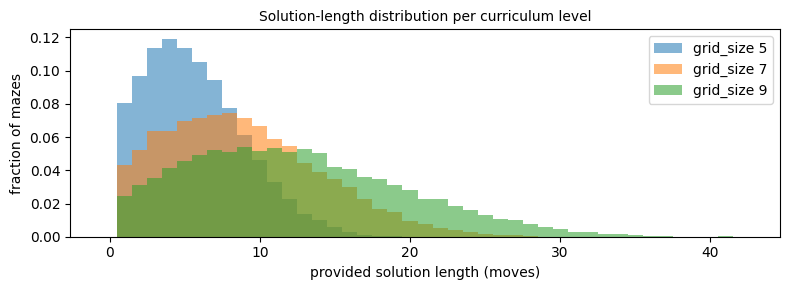

In [16]:
# ======================= 1. Load, document and inspect the dataset =======================
CONFIG = dict(
    hf_id="selimaktas/maze-curriculum-dataset",
    license="MIT",
    week1_level=5,              # grid_size 5 -> ASCII 11x11 (easy curriculum level)
    n_train=4000, n_val=1000, n_test=1000,
    n_probe=1000,               # per harder level, Section 10 only
    seed=0,
)
print(json.dumps(CONFIG, indent=2))

raw = datasets.load_dataset(CONFIG["hf_id"])["train"]
MAZES, SOLS, LEVELS = list(raw["maze"]), list(raw["solution"]), list(raw["grid_size"])  # cached columns
print("columns:", raw.column_names, "| rows:", len(raw))

ex = raw[0]
print("\nprompt[:60]:", repr(ex["prompt"][:60]), "...")
print("grid_size:", ex["grid_size"], "| provided solution:", repr(ex["solution"]))
print(ex["maze"])

# ---- per-level inspection: sizes and solution-label statistics ----
print("%-6s %8s %10s %12s %12s %12s" % ("level", "mazes", "ASCII", "moves mean", "moves med", "moves max"))
level_moves = {}
for lv in sorted(set(LEVELS)):
    idx = [i for i, g in enumerate(LEVELS) if g == lv]
    mv = np.array([len(SOLS[i]) for i in idx])
    level_moves[lv] = mv
    h = len([ln for ln in MAZES[idx[0]].split("\n") if ln.strip()])
    print("%-6d %8d %10s %12.1f %12d %12d" % (lv, len(idx), "%dx%d" % (h, h), mv.mean(),
                                               np.median(mv), mv.max()))

fig, ax = plt.subplots(figsize=(8, 3))
for lv, mv in level_moves.items():
    ax.hist(mv, bins=np.arange(0, mv.max() + 2) - 0.5, alpha=0.55, density=True,
            label="grid_size %d" % lv)
ax.set_xlabel("provided solution length (moves)")
ax.set_ylabel("fraction of mazes")
ax.set_title("Solution-length distribution per curriculum level")
ax.legend()
plt.tight_layout()
plt.show()

## 2) Data adapter (P0)

Pure functions, **no search of any kind**:

- `parse_maze` - ASCII string -> wall grid (1 = wall) + start / goal coordinates;
- `maze_to_channels` - model input `x` with 3 channels `[walkable, start one-hot, goal one-hot]`;
- `replay_solution` - the **provided** move string is replayed literally from `S`. Every move must
  stay inside the grid and neither the passage cell nor the landing cell may be a wall. Every
  traversed ASCII cell is marked -> solution mask `y`. The function also returns the end cell (must
  be exactly `E`) and whether a cell was revisited (must not happen in a simple path);
- `MazeDataset` - a `torch.utils.data.Dataset` over a list of row indices. It yields `(x, y)`
  pairs for the `DataLoader` and keeps per-sample metadata (walls, start, goal, solution) for
  evaluation and plotting.

adapter demo OK | x: (3, 11, 11) | path cells in y: 7 | moves: 3 -> 2*moves+1 = 7
DataLoader batch: x (4, 3, 11, 11) torch.float32 | y (4, 11, 11) torch.float32


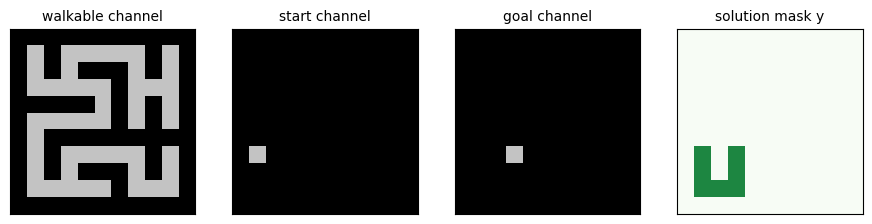

In [17]:
# ======================= 2. Adapter: ASCII -> tensors, provided solution -> mask =======================
DELTAS = {"N": (-2, 0), "S": (2, 0), "E": (0, 2), "W": (0, -2)}


def parse_maze(maze_str):
    # ASCII maze -> wall grid (int8, 1 = wall), start (r, c), goal (r, c)
    lines = [ln for ln in maze_str.split("\n") if ln.strip()]
    H, W = len(lines), len(lines[0])
    wall = np.zeros((H, W), np.int8)
    start = goal = None
    for r, line in enumerate(lines):
        for c, ch in enumerate(line):
            if ch == "#":
                wall[r, c] = 1
            elif ch == "S":
                start = (r, c)
            elif ch == "E":
                goal = (r, c)
    return wall, start, goal


def maze_to_channels(wall, start, goal):
    # wall grid + endpoints -> model input (3, H, W): walkable, start one-hot, goal one-hot
    walk = (wall == 0).astype(np.float32)
    s = np.zeros(wall.shape, np.float32)
    s[start] = 1.0
    g = np.zeros(wall.shape, np.float32)
    g[goal] = 1.0
    return np.stack([walk, s, g])


def replay_solution(wall, start, solution):
    # PROVIDED move string -> path mask by pure rule-following (no search).
    # Returns (mask, end_cell, legal, revisited).
    H, W = wall.shape
    mask = np.zeros((H, W), bool)
    mask[start] = True
    r, c = start
    revisited = False
    for mv in solution:
        if mv not in DELTAS:
            return mask, (r, c), False, revisited
        dr, dc = DELTAS[mv]
        nr, nc = r + dr, c + dc
        if not (0 <= nr < H and 0 <= nc < W):
            return mask, (r, c), False, revisited
        if wall[r + dr // 2, c + dc // 2] or wall[nr, nc]:
            return mask, (r, c), False, revisited
        revisited |= bool(mask[nr, nc])
        mask[r + dr // 2, c + dc // 2] = True
        mask[nr, nc] = True
        r, c = nr, nc
    return mask, (r, c), True, revisited


class MazeDataset(Dataset):
    # (x, y) pairs for training + per-sample metadata for evaluation / plots
    def __init__(self, indices):
        self.indices = list(indices)
        xs, ys = [], []
        self.walls, self.starts, self.goals, self.solutions = [], [], [], []
        for i in self.indices:
            wall, start, goal = parse_maze(MAZES[i])
            mask, end, legal, revisited = replay_solution(wall, start, SOLS[i])
            if not legal or end != goal or revisited:
                raise ValueError("row %d: provided solution does not replay to E" % i)
            xs.append(maze_to_channels(wall, start, goal))
            ys.append(mask.astype(np.float32))
            self.walls.append(wall)
            self.starts.append(start)
            self.goals.append(goal)
            self.solutions.append(SOLS[i])
        self.x = torch.from_numpy(np.stack(xs))
        self.y = torch.from_numpy(np.stack(ys))

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, k):
        return self.x[k], self.y[k]


# ---- adapter demo on row 0 ----
wall, start, goal = parse_maze(ex["maze"])
x_demo = maze_to_channels(wall, start, goal)
mask_demo, end, legal, revisited = replay_solution(wall, start, ex["solution"])
assert legal and end == goal and not revisited
assert not (mask_demo & (wall == 1)).any(), "the path must not touch walls"
print("adapter demo OK | x:", x_demo.shape, "| path cells in y:", int(mask_demo.sum()),
      "| moves:", len(ex["solution"]), "-> 2*moves+1 =", 2 * len(ex["solution"]) + 1)

demo_ds = MazeDataset([0, 1, 2, 3])
xb, yb = next(iter(DataLoader(demo_ds, batch_size=4)))
print("DataLoader batch: x", tuple(xb.shape), xb.dtype, "| y", tuple(yb.shape), yb.dtype)

fig, axes = plt.subplots(1, 4, figsize=(11, 3.0))
for ax, ch, ttl in zip(axes, list(x_demo) + [mask_demo.astype(float)],
                       ["walkable channel", "start channel", "goal channel", "solution mask y"]):
    ax.imshow(ch, cmap="Greens" if "mask" in ttl else "gray", vmin=0, vmax=1.3)
    ax.set_title(ttl)
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

## 3) Dataset validation (P0)

Every one of the **60,000** mazes (all three levels) is checked - all by rule-following or
union-find bookkeeping, no search:

| # | check | what it guarantees |
|---|---|---|
| 1 | rectangular `(2N+1) x (2N+1)` grid matching `grid_size` | consistent tensor shapes |
| 2 | exactly one `S` and one `E` | well-defined endpoints |
| 3 | `S`, `E` on navigable (odd, odd) lattice cells, `S != E` | endpoints on free cells |
| 4 | outer border is all wall | no escape through the boundary |
| 5 | lattice structure: all (odd, odd) cells free, all (even, even) pillars wall | ASCII geometry as documented |
| 6 | **perfect maze**: the passage graph is a spanning tree (union-find: no cycle and exactly `N*N - 1` passages) | every free cell is **connected**, and the S-to-E path is **unique** |
| 7 | provided solution replays legally (in bounds, no wall in passage or landing cell) | no **wall collisions** |
| 8 | replay ends **exactly** on `E` | the label reaches the goal |
| 9 | replay never revisits a cell | simple path; with check 6 it is *the* unique shortest path |
| 10 | no duplicates - exact string **and** up to the 8 rotations/reflections | no train/test leakage via symmetric copies |

After validation the Week-1 split is drawn from the valid level-5 pool with a fixed seed, and
**zero overlap** (including symmetric copies) between train / val / test is asserted.

In [18]:
# ======================= 3. Validate all 60k samples; build the split =======================
def _root(parent, a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]
        a = parent[a]
    return a


def is_perfect_maze(wall):
    # union-find over navigable cells: perfect <=> no cycle and exactly n*n - 1 open passages
    H, W = wall.shape
    n = (H - 1) // 2
    parent = list(range(n * n))
    passages = 0
    for r in range(1, H - 1, 2):
        for c in range(1, W - 1, 2):
            for dr, dc in ((0, 1), (1, 0)):
                if r + 2 * dr < H - 1 and c + 2 * dc < W - 1 and wall[r + dr, c + dc] == 0:
                    a = _root(parent, (r // 2) * n + c // 2)
                    b = _root(parent, ((r + 2 * dr) // 2) * n + (c + 2 * dc) // 2)
                    if a == b:
                        return False          # cycle -> more than one route
                    parent[a] = b
                    passages += 1
    return passages == n * n - 1             # spanning tree -> connected


def canonical_key(maze_str):
    # identical up to the 8 rotations / reflections -> same key
    lines = [ln for ln in maze_str.split("\n") if ln.strip()]
    A = np.frombuffer("".join(lines).encode(), np.uint8).reshape(len(lines), -1)
    views = []
    for k in range(4):
        R = np.rot90(A, k)
        views += [R.tobytes(), R[:, ::-1].tobytes()]
    return min(views)


CHECKS = ["shape", "one S / one E", "endpoints on lattice", "border", "lattice",
          "perfect maze", "legal replay", "ends on E", "simple path"]


def validate_example(maze_str, solution, n):
    lines = [ln for ln in maze_str.split("\n") if ln.strip()]
    if len(lines) != 2 * n + 1 or any(len(ln) != 2 * n + 1 for ln in lines):
        return ["shape"]
    if maze_str.count("S") != 1 or maze_str.count("E") != 1:
        return ["one S / one E"]
    wall, s, g = parse_maze(maze_str)
    fails = []
    if s == g or not all(v % 2 == 1 for v in s + g):
        fails.append("endpoints on lattice")
    if not (wall[0].all() and wall[-1].all() and wall[:, 0].all() and wall[:, -1].all()):
        fails.append("border")
    if wall[1::2, 1::2].any() or not wall[::2, ::2].all():
        fails.append("lattice")
    if not is_perfect_maze(wall):
        fails.append("perfect maze")
    mask, end, legal, revisited = replay_solution(wall, s, solution)
    if not legal:
        fails.append("legal replay")
    elif end != g:
        fails.append("ends on E")
    if revisited:
        fails.append("simple path")
    return fails


t0 = time.time()
fail_counts = {lv: Counter() for lv in sorted(set(LEVELS))}
valid = {lv: [] for lv in fail_counts}
exact_seen, canon_seen = {}, {}
exact_dups = canon_dups = 0
for i, (m, sol, lv) in enumerate(zip(MAZES, SOLS, LEVELS)):
    fails = validate_example(m, sol, lv)
    if m in exact_seen:
        exact_dups += 1
        fails.append("duplicate (exact)")
    else:
        exact_seen[m] = i
    key = canonical_key(m)
    if key in canon_seen and "duplicate (exact)" not in fails:
        canon_dups += 1
        fails.append("duplicate (symmetry)")
    canon_seen.setdefault(key, i)
    for f in fails:
        fail_counts[lv][f] += 1
    if not fails:
        valid[lv].append(i)
print("validated %d mazes in %.1fs" % (len(MAZES), time.time() - t0))

print("\n%-26s" % "check" + "".join("%12s" % ("level %d" % lv) for lv in fail_counts))
for chk in CHECKS + ["duplicate (exact)", "duplicate (symmetry)"]:
    print("%-26s" % ("failures: " + chk) + "".join("%12d" % fail_counts[lv][chk] for lv in fail_counts))
print("%-26s" % "VALID samples" + "".join("%12d" % len(valid[lv]) for lv in fail_counts))
print("%-26s" % "total in dataset" + "".join("%12d" % LEVELS.count(lv) for lv in fail_counts))

# ---- seeded split of the valid level-5 pool ----
rng = np.random.default_rng(CONFIG["seed"])
pool = valid[CONFIG["week1_level"]]
perm = rng.permutation(len(pool))
n_tr, n_va, n_te = CONFIG["n_train"], CONFIG["n_val"], CONFIG["n_test"]
pick = [pool[j] for j in perm[: n_tr + n_va + n_te]]
splits = {"train": pick[:n_tr], "val": pick[n_tr:n_tr + n_va], "test": pick[n_tr + n_va:]}

keys = {k: {canonical_key(MAZES[i]) for i in v} for k, v in splits.items()}
assert not (keys["train"] & keys["val"]) and not (keys["train"] & keys["test"]) \
    and not (keys["val"] & keys["test"]), "split leakage"
print("\nsplit sizes:", {k: len(v) for k, v in splits.items()}, "| leakage (incl. symmetric copies): 0")

ds = {name: MazeDataset(idx) for name, idx in splits.items()}
# harder levels, used only by the Section-10 probe (never for training)
probe = {lv: MazeDataset([valid[lv][j] for j in rng.permutation(len(valid[lv]))[:CONFIG["n_probe"]]])
         for lv in (7, 9)}
for name, d in ds.items():
    print("%-5s x %s | y %s" % (name, tuple(d.x.shape), tuple(d.y.shape)))
for lv, d in probe.items():
    print("probe level %d: x %s" % (lv, tuple(d.x.shape)))

# ---- label statistics (training split) ----
density = ds["train"].y.mean().item()
pos_weight = (1.0 - density) / density
lens = np.array([len(s) for s in ds["train"].solutions])
cells = ds["train"].y.sum(dim=(1, 2)).numpy()
free = ds["train"].x[:, 0].sum(dim=(1, 2)).numpy()
print("\ntrain: solution moves mean %.1f | max %d" % (lens.mean(), lens.max()))
print("train: path cells per mask mean %.1f of %.0f free cells (label = %.1f%% of free cells, %.1f%% of all cells)"
      % (cells.mean(), free.mean(), 100 * (cells / free).mean(), 100 * density))
print("pos_weight for BCE (from train label density over all cells) = %.2f" % pos_weight)

validated 60000 mazes in 13.4s

check                          level 5     level 7     level 9
failures: shape                      0           0           0
failures: one S / one E              0           0           0
failures: endpoints on lattice           0           0           0
failures: border                     0           0           0
failures: lattice                    0           0           0
failures: perfect maze               0           0           0
failures: legal replay               0           0           0
failures: ends on E                  0           0           0
failures: simple path                0           0           0
failures: duplicate (exact)           0           0           0
failures: duplicate (symmetry)           0           0           0
VALID samples                    25000       20000       15000
total in dataset                 25000       20000       15000

split sizes: {'train': 4000, 'val': 1000, 'test': 1000} | leakage (incl. sym

## 4) Strict evaluation metric (P0)

A prediction (thresholded probability map) counts as a **strict maze-solving success** iff the
set of predicted cells is **exactly one legal, optimal path from S to G**:

1. **no wall cells** are predicted;
2. **S and G are predicted**, and following the predicted cells from S is unambiguous: every step
   has exactly one predicted 4-neighbour other than the cell we came from (no branch, no dead end),
   and the trace arrives at G, where G has exactly one predicted neighbour;
3. the traced path uses **every** predicted cell - no extra cells, spurs or islands anywhere;
4. the path length equals the length of the provided solution path (optimality).

This check is **search-free** (a deterministic trace, at most `H*W` steps) and does not even need
the label except for the optimality length. In a perfect maze the legal S-to-G path is unique, so
`strict` must coincide with exact mask agreement on every sample - asserted below and in every
evaluation.

Reported alongside:

| metric | meaning |
|---|---|
| `exact` | predicted mask == label mask on all cells |
| `iou`, `precision`, `recall` | cell-level overlap with the label |
| `covers_path` | **connectivity-style lenient metric** (v1's "strict"): all label cells predicted and no wall hits, extra cells allowed |
| `wall_hits`, `extra_cells`, `missed_cells` | error counts per maze |

The self-tests show why the lenient metric is insufficient: predicting **all free cells**, a
spur or a disconnected island all "solve" the maze under `covers_path`, but fail `strict`.

case                    strict  covers_path    IoU
ground truth                 1            1   1.00
empty                        0            0   0.00
all free cells               0            1   0.10
GT + wall cell               0            0   0.83
GT + spur                    0            1   0.83
GT - one cell (gap)          0            0   0.80
GT + island                  0            1   0.83


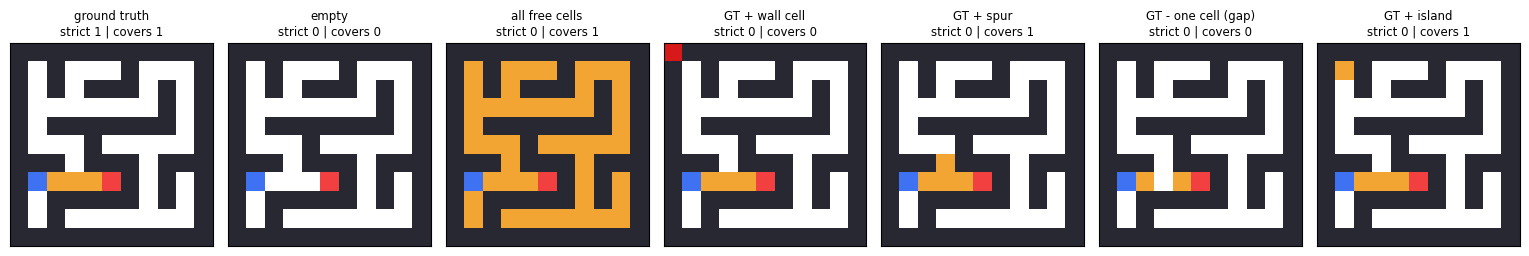

metric self-tests passed: only the exact legal path is a strict success


In [19]:
# ======================= 4. Strict evaluation functions (no search) =======================
NBR4 = ((-1, 0), (1, 0), (0, -1), (0, 1))


def _pred_neighbours(pred, cell):
    H, W = pred.shape
    out = []
    for dr, dc in NBR4:
        r, c = cell[0] + dr, cell[1] + dc
        if 0 <= r < H and 0 <= c < W and pred[r, c]:
            out.append((r, c))
    return out


def trace_path(pred, start, goal):
    # deterministic trace S -> G through predicted cells; None if ambiguous / broken
    if not pred[start] or not pred[goal] or start == goal:
        return None
    path, prev, cur, limit = [start], None, start, int(pred.sum())
    while cur != goal:
        nxt = [n for n in _pred_neighbours(pred, cur) if n != prev]
        if len(nxt) != 1:
            return None                       # dead end or branch
        prev, cur = cur, nxt[0]
        path.append(cur)
        if len(path) > limit:
            return None                       # cycle guard
    if len(_pred_neighbours(pred, goal)) != 1:
        return None                           # G must be an endpoint
    return path


def evaluate_mask(pred, wall, start, goal, y):
    # pred: bool (H, W); wall: int8 (1 = wall); y: float/bool label mask (H, W) - all NumPy
    pred = np.asarray(pred, bool)
    gt = np.asarray(y) > 0.5
    free = wall == 0
    wall_hits = int((pred & ~free).sum())
    path = trace_path(pred, start, goal)
    single_path = path is not None and len(path) == int(pred.sum())
    strict = wall_hits == 0 and single_path and len(path) == int(gt.sum())
    tp = int((pred & gt).sum())
    fp = int((pred & ~gt).sum())
    fn = int((~pred & gt).sum())
    return dict(
        strict=int(strict),
        exact=int((pred == gt).all()),
        iou=tp / max(tp + fp + fn, 1),
        precision=tp / max(tp + fp, 1),
        recall=tp / max(tp + fn, 1),
        covers_path=int(fn == 0 and wall_hits == 0),
        wall_hits=wall_hits,
        extra_cells=fp,
        missed_cells=fn,
    )


def summarize(rows):
    return {k: float(np.mean([r[k] for r in rows])) for k in rows[0]}


# ---- self-tests of the metric itself, on a validation maze ----
def _metric_test_cases(k):
    d = ds["val"]
    wall, s, g, y = d.walls[k], d.starts[k], d.goals[k], d.y[k].numpy()
    gt = y > 0.5
    free = wall == 0
    path = trace_path(gt, s, g)
    near = [c for c in zip(*np.where(free & ~gt)) if any(gt[n] for n in _pred_neighbours(free, c))]
    far = [c for c in zip(*np.where(free & ~gt))
           if not any(gt[n] for n in _pred_neighbours(free, c))]
    if path is None or len(path) < 5 or not near or not far:
        return None
    gap = gt.copy(); gap[path[len(path) // 2]] = False
    spur = gt.copy(); spur[near[0]] = True
    island = gt.copy(); island[far[0]] = True
    wallhit = gt.copy(); wallhit[np.argwhere(wall == 1)[0][0], np.argwhere(wall == 1)[0][1]] = True
    cases = [("ground truth", gt, 1), ("empty", np.zeros_like(gt), 0), ("all free cells", free, 0),
             ("GT + wall cell", wallhit, 0), ("GT + spur", spur, 0), ("GT - one cell (gap)", gap, 0),
             ("GT + island", island, 0)]
    return (wall, s, g, y), cases


k = 0
while _metric_test_cases(k) is None:
    k += 1
(wall_t, s_t, g_t, y_t), cases = _metric_test_cases(k)
fig, axes = plt.subplots(1, len(cases), figsize=(2.2 * len(cases), 2.9))
print("%-22s %7s %12s %6s" % ("case", "strict", "covers_path", "IoU"))
for ax, (name, pred, expected) in zip(axes, cases):
    r = evaluate_mask(pred, wall_t, s_t, g_t, y_t)
    assert r["strict"] == expected, name
    assert r["strict"] == r["exact"] or name == "ground truth"
    print("%-22s %7d %12d %6.2f" % (name, r["strict"], r["covers_path"], r["iou"]))
    img = np.ones(wall_t.shape + (3,))
    img[wall_t == 1] = (0.16, 0.16, 0.2)
    img[pred & (wall_t == 0)] = (0.95, 0.65, 0.2)
    img[pred & (wall_t == 1)] = (0.85, 0.1, 0.1)
    img[s_t] = (0.95, 0.25, 0.25); img[g_t] = (0.25, 0.45, 0.95)
    ax.imshow(img)
    ax.set_title("%s\nstrict %d | covers %d" % (name, r["strict"], r["covers_path"]), fontsize=8.5)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()
print("metric self-tests passed: only the exact legal path is a strict success")

## 5) Training setup and documented hyperparameters

Shared by all models, so later CF variants (Week 2) can be trained and evaluated with **identical
data, loss, optimiser and metric** - any model with `forward(x, T) -> logits (B, H, W)` plugs in.

- **Loss:** `BCEWithLogits` over all cells with `pos_weight` = negative/positive ratio of the
  training labels (path cells are about 10% of all cells).
- **Optimiser:** Adam, cosine learning-rate decay to 0 over training, gradient-norm clipping.
  (Without decay and clipping the recurrent model showed large mid-training collapses in the
  hyperparameter sanity runs.)
- **Model selection:** the checkpoint with the best **validation strict accuracy** (ties: IoU) is
  kept; the test split is touched only for final reporting.
- **Seeds:** 3 seeds per model (seed controls weight init and batch order; the data split is fixed).

In [20]:
# ======================= 5. Hyperparameters, models, train / evaluate utilities =======================
HYPERPARAMS = dict(
    optimizer="Adam", lr=1e-3, lr_schedule="cosine decay to 0 (per step)", grad_clip_norm=1.0,
    batch_size=32, epochs=40,
    loss="BCEWithLogits over all cells, pos_weight = neg/pos ratio of train labels",
    pos_weight=round(pos_weight, 2), threshold=0.5,
    T_train_recurrent=8, model_selection="best val strict (ties: val IoU)",
    seeds=[0, 1, 2],
)
MODEL_CFG = {"RecurrentCNN": dict(hid=22), "PlainCNN": dict(hid=18, depth=6)}
print(json.dumps(dict(HYPERPARAMS, models=MODEL_CFG), indent=2))


class RecurrentCNN(nn.Module):
    # weight-shared residual conv cell with per-step input injection
    # (identical to maze_cf.RecurrentCNN from Milestone 1)
    def __init__(self, in_ch=3, hid=22):
        super().__init__()
        self.encoder = nn.Conv2d(in_ch, hid, 3, padding=1)
        self.cell = nn.Sequential(
            nn.Conv2d(in_ch + hid, hid, 3, padding=1),
            nn.GELU(),
            nn.Conv2d(hid, hid, 3, padding=1),
        )
        self.readout = nn.Conv2d(hid, 1, 1)

    def forward(self, x, T=8):
        h = self.encoder(x)
        for _ in range(T):
            h = h + self.cell(torch.cat([x, h], dim=1))
        return self.readout(h).squeeze(1)


class PlainCNN(nn.Module):
    # 5 x (3x3 conv) + 1x1 readout -> receptive field 11x11 (+/-5 cells); no loop, no state
    def __init__(self, in_ch=3, hid=18, depth=6):
        super().__init__()
        layers = [nn.Conv2d(in_ch, hid, 3, padding=1), nn.GELU()]
        for _ in range(depth - 2):
            layers += [nn.Conv2d(hid, hid, 3, padding=1), nn.GELU()]
        layers += [nn.Conv2d(hid, 1, 1)]
        self.net = nn.Sequential(*layers)

    def forward(self, x, T=1):            # T accepted and ignored
        return self.net(x).squeeze(1)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


@torch.no_grad()
def predict_probs(model, d, T, bs=500):
    model.eval()
    out = [torch.sigmoid(model(d.x[i:i + bs].to(DEVICE), T=T)).cpu() for i in range(0, len(d), bs)]
    return torch.cat(out).numpy()


def evaluate_model(model, d, T, thresh=None):
    thresh = HYPERPARAMS["threshold"] if thresh is None else thresh
    probs = predict_probs(model, d, T)
    rows = [evaluate_mask(probs[k] >= thresh, d.walls[k], d.starts[k], d.goals[k], d.y[k].numpy())
            for k in range(len(d))]
    assert all(r["strict"] == r["exact"] for r in rows), "perfect maze: strict must equal exact"
    return summarize(rows), rows, probs


def train_model(make_model, T, seed, tag, verbose=True):
    hp = HYPERPARAMS
    set_seed(seed)
    model = make_model().to(DEVICE)
    gen = torch.Generator().manual_seed(seed)
    loader = DataLoader(ds["train"], batch_size=hp["batch_size"], shuffle=True, generator=gen)
    opt = torch.optim.Adam(model.parameters(), lr=hp["lr"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=hp["epochs"] * len(loader))
    pw = torch.tensor(float(pos_weight), device=DEVICE)
    hist = {k: [] for k in ["train_loss", "val_strict", "val_iou", "val_covers_path"]}
    best_key, best_state = (-1.0, -1.0), None
    t_start = time.time()
    for ep in range(hp["epochs"]):
        model.train()
        total = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            loss = F.binary_cross_entropy_with_logits(model(xb, T=T), yb, pos_weight=pw)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), hp["grad_clip_norm"])
            opt.step()
            sched.step()
            total += float(loss.detach()) * len(xb)
        v, _, _ = evaluate_model(model, ds["val"], T)
        hist["train_loss"].append(total / len(ds["train"]))
        hist["val_strict"].append(v["strict"])
        hist["val_iou"].append(v["iou"])
        hist["val_covers_path"].append(v["covers_path"])
        if (v["strict"], v["iou"]) > best_key:
            best_key = (v["strict"], v["iou"])
            best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}
            hist["best_epoch"] = ep
        if verbose and (ep % 5 == 4 or ep == 0):
            print("  [%s seed %d] epoch %2d | train BCE %.4f | val strict %.3f IoU %.3f covers %.3f"
                  % (tag, seed, ep, hist["train_loss"][-1], v["strict"], v["iou"], v["covers_path"]))
    model.load_state_dict(best_state)
    hist["train_time_s"] = time.time() - t_start
    ckpt = RESULTS / ("%s_seed%d.pt" % (tag, seed))
    torch.save(model.state_dict(), str(ckpt))
    if verbose:
        print("  [%s seed %d] best epoch %d (val strict %.3f) | %.0fs | saved %s"
              % (tag, seed, hist["best_epoch"], best_key[0], hist["train_time_s"], ckpt.name))
    return model, hist


def plot_history(hist, title):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3))
    a1.plot(hist["train_loss"]); a1.set_yscale("log")
    a1.set_xlabel("epoch"); a1.set_ylabel("train BCE (log)"); a1.set_title(title + ": training loss")
    a2.plot(hist["val_strict"], label="val strict (exact path)")
    a2.plot(hist["val_covers_path"], "--", label="val covers_path (lenient)")
    a2.plot(hist["val_iou"], ":", label="val IoU")
    a2.axvline(hist["best_epoch"], color="grey", lw=0.8)
    a2.set_ylim(0, 1.02); a2.set_xlabel("epoch"); a2.legend(fontsize=8)
    a2.set_title(title + ": validation (grey = selected epoch)")
    plt.tight_layout()
    plt.show()

{
  "optimizer": "Adam",
  "lr": 0.001,
  "lr_schedule": "cosine decay to 0 (per step)",
  "grad_clip_norm": 1.0,
  "batch_size": 32,
  "epochs": 40,
  "loss": "BCEWithLogits over all cells, pos_weight = neg/pos ratio of train labels",
  "pos_weight": 8.76,
  "threshold": 0.5,
  "T_train_recurrent": 8,
  "model_selection": "best val strict (ties: val IoU)",
  "seeds": [
    0,
    1,
    2
  ],
  "models": {
    "RecurrentCNN": {
      "hid": 22
    },
    "PlainCNN": {
      "hid": 18,
      "depth": 6
    }
  }
}


## 6) First baseline: RecurrentCNN (P0)

The looped-processor control from Milestone 1 (`maze_cf.RecurrentCNN`, defined inline here),
about 10k parameters, unrolled **T = 8** steps during training, trained on the easy 5x5
(ASCII 11x11) mazes. Seed 0 is trained and inspected here; seeds 1-2 follow in Section 9.

RecurrentCNN params: 9989
  [recurrent_cnn seed 0] epoch  0 | train BCE 0.6127 | val strict 0.000 IoU 0.336 covers 0.950
  [recurrent_cnn seed 0] epoch  4 | train BCE 0.3710 | val strict 0.007 IoU 0.514 covers 0.825
  [recurrent_cnn seed 0] epoch  9 | train BCE 0.2102 | val strict 0.093 IoU 0.687 covers 0.866
  [recurrent_cnn seed 0] epoch 14 | train BCE 0.1031 | val strict 0.383 IoU 0.820 covers 0.974
  [recurrent_cnn seed 0] epoch 19 | train BCE 0.0422 | val strict 0.691 IoU 0.933 covers 0.983
  [recurrent_cnn seed 0] epoch 24 | train BCE 0.0130 | val strict 0.888 IoU 0.984 covers 0.971
  [recurrent_cnn seed 0] epoch 29 | train BCE 0.0039 | val strict 0.911 IoU 0.988 covers 0.976
  [recurrent_cnn seed 0] epoch 34 | train BCE 0.0015 | val strict 0.939 IoU 0.991 covers 0.984
  [recurrent_cnn seed 0] epoch 39 | train BCE 0.0011 | val strict 0.944 IoU 0.992 covers 0.982
  [recurrent_cnn seed 0] best epoch 39 (val strict 0.944) | 412s | saved recurrent_cnn_seed0.pt


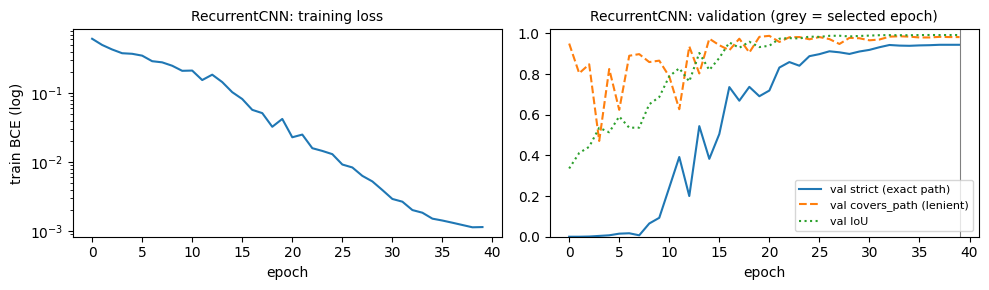

In [21]:
# ======================= 6. Train the RecurrentCNN baseline (seed 0) =======================
T_REC = HYPERPARAMS["T_train_recurrent"]
make_rcnn = lambda: RecurrentCNN(**MODEL_CFG["RecurrentCNN"])
print("RecurrentCNN params:", n_params(make_rcnn()))
rcnn, rcnn_hist = train_model(make_rcnn, T=T_REC, seed=0, tag="recurrent_cnn")
plot_history(rcnn_hist, "RecurrentCNN")

## 7) RecurrentCNN results: held-out test, running example, successes and failures

The **running example** shows, for test mazes, the input maze (S red, G blue), the target
(provided-solution mask), the model's probability map, the thresholded prediction and an error map.

RecurrentCNN (seed 0, T=8), held-out test split (n=1000):
{'strict': 0.945, 'exact': 0.945, 'iou': 0.993, 'precision': 0.995, 'recall': 0.998, 'covers_path': 0.981, 'wall_hits': 0.0, 'extra_cells': 0.081, 'missed_cells': 0.039}


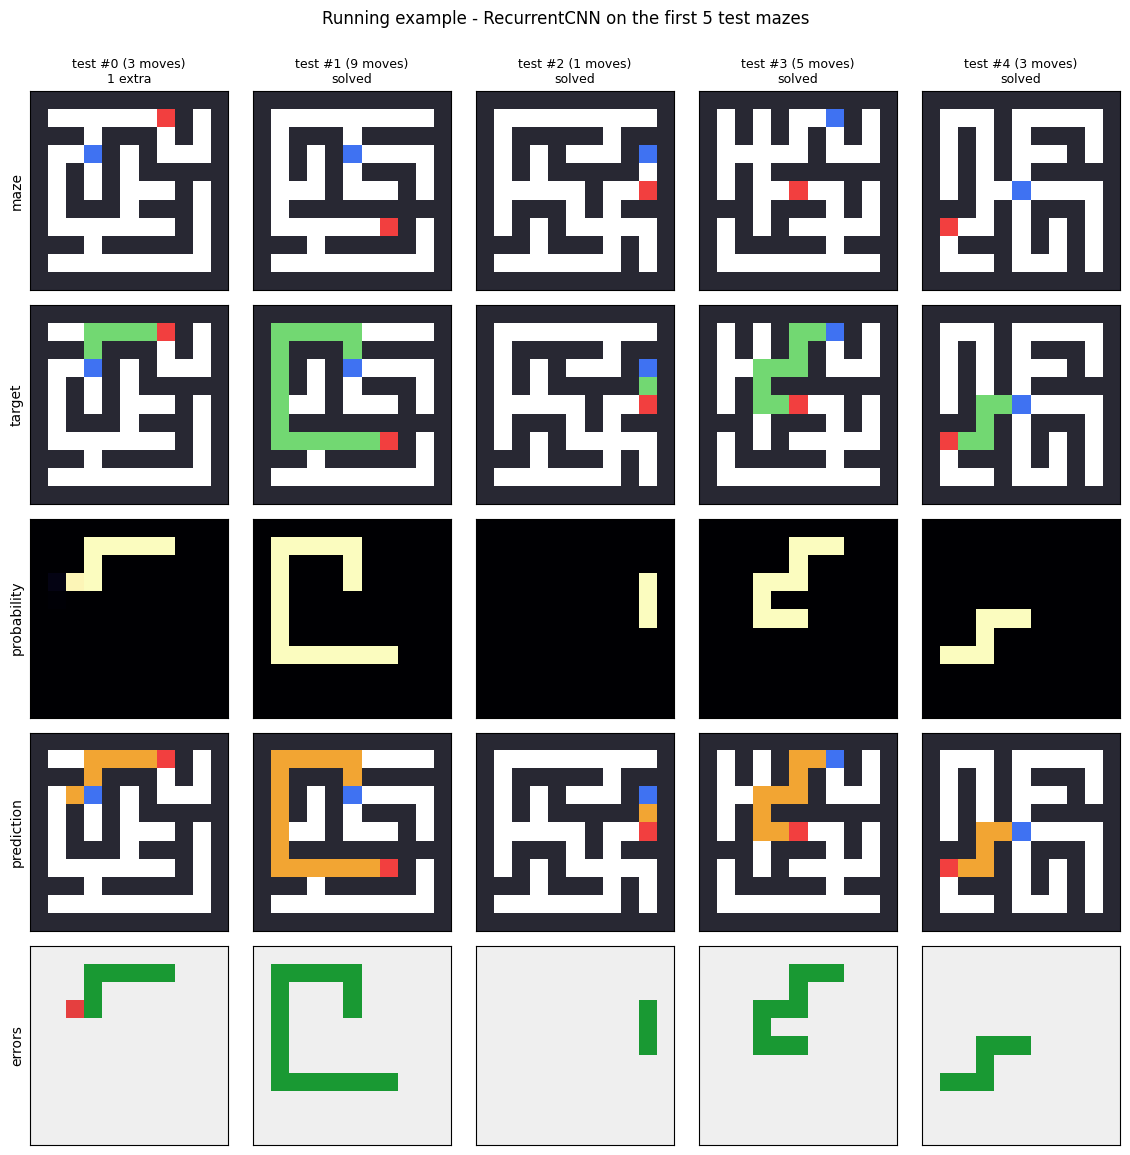

error map: dark green = hit | red = false positive | blue = missed cell | grey = correct negative
solved 945 / failed 55 test mazes
failure types: {'extra cells only (spur / island)': 36, 'missed + extra cells (wrong branch)': 2, 'missed cells only (gap)': 17}


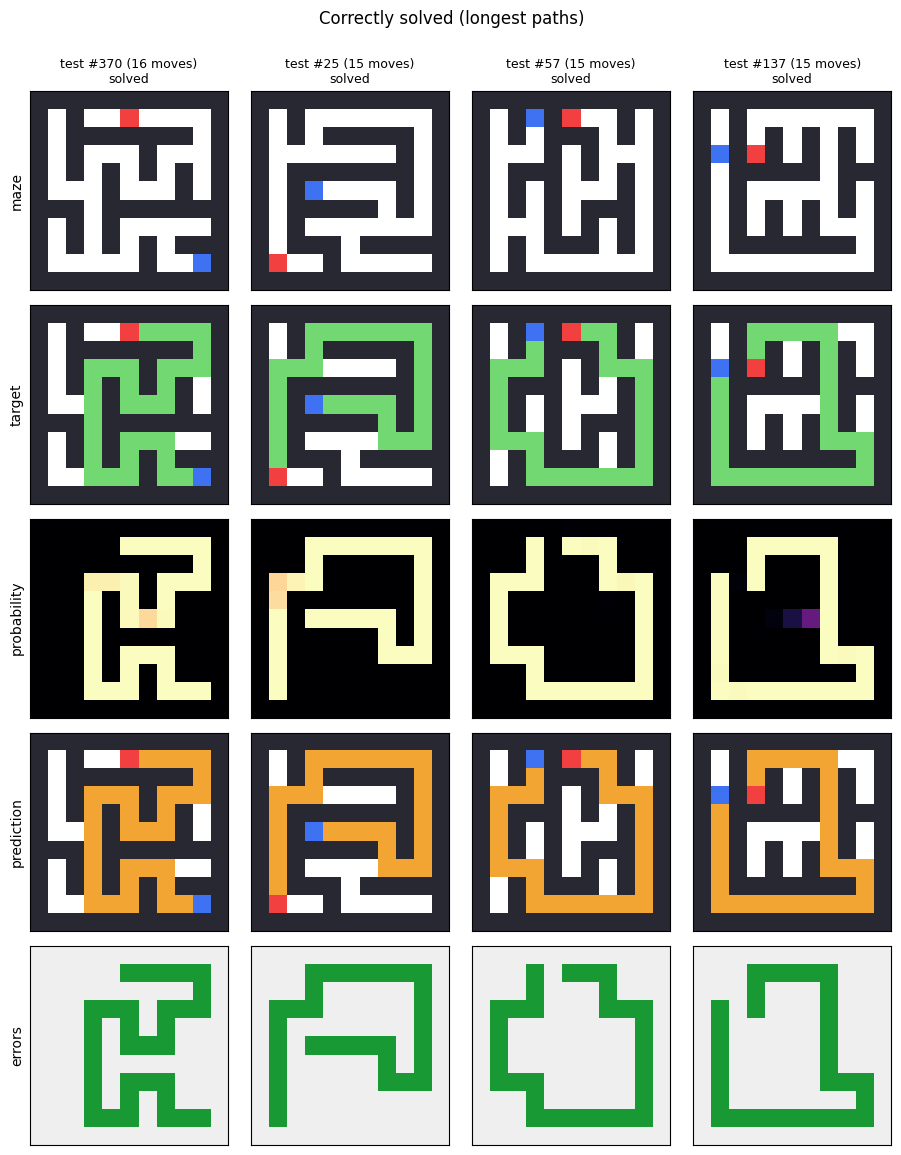

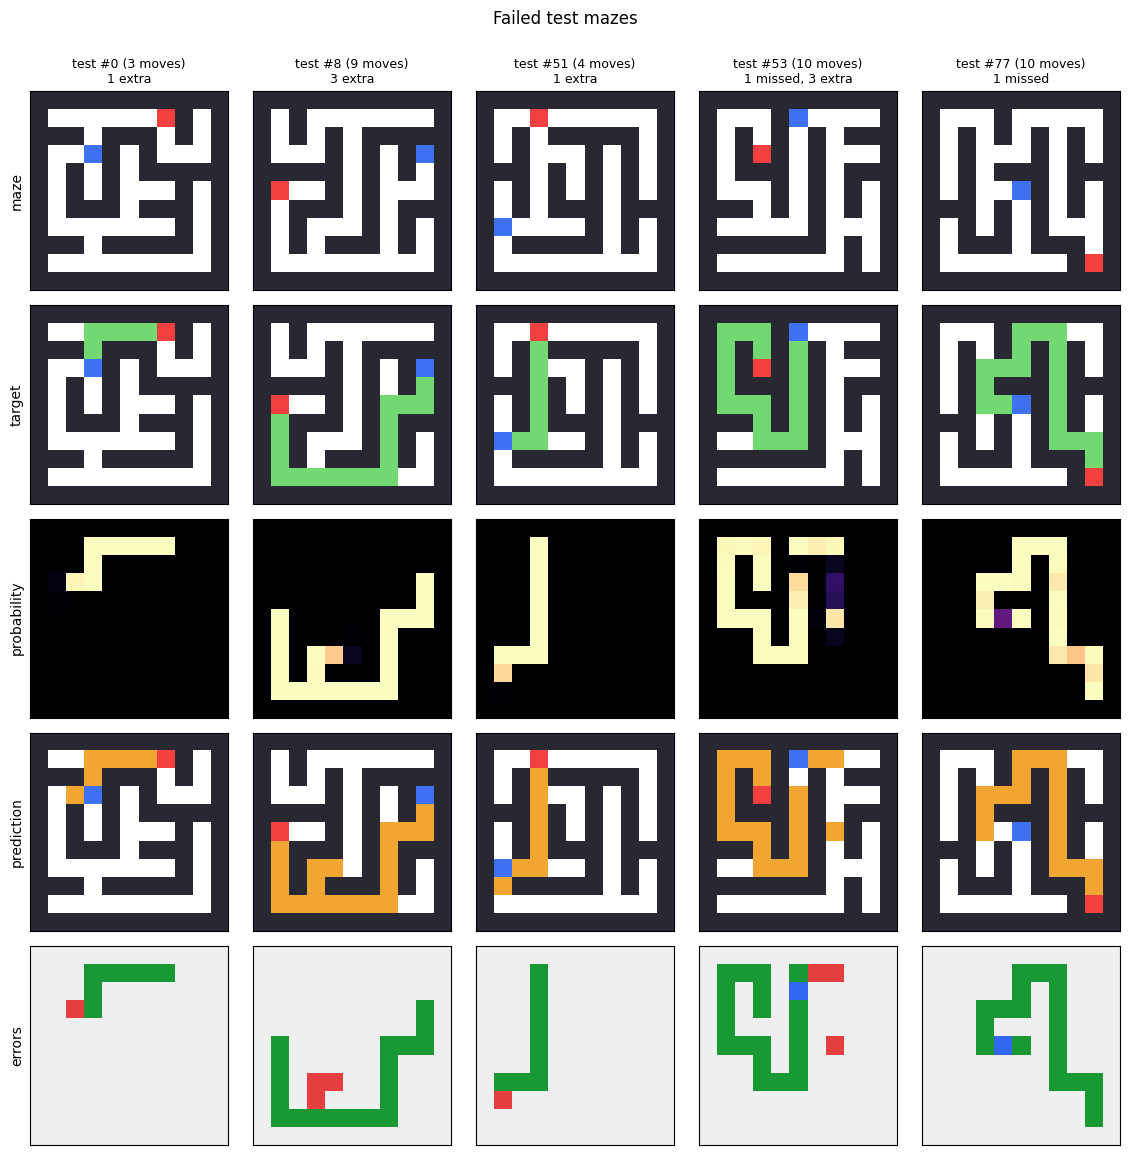


strict accuracy by provided-solution length (moves):
  1-3    n= 292  strict 0.983
  4-5    n= 222  strict 0.968
  6-7    n= 190  strict 0.921
  8-9    n= 152  strict 0.901
  10-12  n= 108  strict 0.935
  13-20  n=  36  strict 0.833


In [22]:
# ======================= 7. Held-out results + running example + failure analysis =======================
rcnn_test, rcnn_rows, rcnn_probs = evaluate_model(rcnn, ds["test"], T=T_REC)
print("RecurrentCNN (seed 0, T=%d), held-out test split (n=%d):" % (T_REC, len(ds["test"])))
print({k: round(v, 3) for k, v in rcnn_test.items()})


def maze_rgb(wall, start, goal, mask=None, color=(0.45, 0.85, 0.45)):
    img = np.ones(wall.shape + (3,))
    img[wall == 1] = (0.16, 0.16, 0.20)
    if mask is not None:
        img[mask] = color
    img[start] = (0.95, 0.25, 0.25)
    img[goal] = (0.25, 0.45, 0.95)
    return img


def error_rgb(pred, gt):
    img = np.full(gt.shape + (3,), 0.94)
    img[pred & gt] = (0.1, 0.6, 0.2)       # hit
    img[pred & ~gt] = (0.9, 0.25, 0.25)    # false positive
    img[gt & ~pred] = (0.2, 0.4, 0.95)     # missed
    return img


def failure_reason(r):
    if r["strict"]:
        return "solved"
    parts = []
    if r["wall_hits"]:
        parts.append("wall hit")
    if r["missed_cells"]:
        parts.append("%d missed" % r["missed_cells"])
    if r["extra_cells"]:
        parts.append("%d extra" % r["extra_cells"])
    return ", ".join(parts)


def show_examples(d, probs, rows, ks, title):
    fig, axes = plt.subplots(5, len(ks), figsize=(2.3 * len(ks), 11.5), squeeze=False)
    for j, k in enumerate(ks):
        gt = d.y[k].numpy() > 0.5
        pred = probs[k] >= HYPERPARAMS["threshold"]
        w, s, g = d.walls[k], d.starts[k], d.goals[k]
        axes[0, j].imshow(maze_rgb(w, s, g))
        axes[1, j].imshow(maze_rgb(w, s, g, gt))
        axes[2, j].imshow(probs[k], cmap="magma", vmin=0, vmax=1)
        axes[3, j].imshow(maze_rgb(w, s, g, pred, color=(0.95, 0.65, 0.2)))
        axes[4, j].imshow(error_rgb(pred, gt))
        axes[0, j].set_title("test #%d (%d moves)\n%s" % (k, len(d.solutions[k]),
                                                          failure_reason(rows[k])), fontsize=9)
        for i in range(5):
            axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
    for i, lab in enumerate(["maze", "target", "probability", "prediction", "errors"]):
        axes[i, 0].set_ylabel(lab)
    fig.suptitle(title, y=1.0)
    plt.tight_layout()
    plt.show()


show_examples(ds["test"], rcnn_probs, rcnn_rows, list(range(5)),
              "Running example - RecurrentCNN on the first 5 test mazes")
print("error map: dark green = hit | red = false positive | blue = missed cell | grey = correct negative")

solved = [k for k, r in enumerate(rcnn_rows) if r["strict"]]
failed = [k for k, r in enumerate(rcnn_rows) if not r["strict"]]
print("solved %d / failed %d test mazes" % (len(solved), len(failed)))
def failure_type(r):
    if r["wall_hits"]:
        return "wall hit"
    if r["missed_cells"] and r["extra_cells"]:
        return "missed + extra cells (wrong branch)"
    return "missed cells only (gap)" if r["missed_cells"] else "extra cells only (spur / island)"


print("failure types:", dict(Counter(failure_type(rcnn_rows[k]) for k in failed)))
# longest solved and failed mazes are the most informative
solved_long = sorted(solved, key=lambda k: -len(ds["test"].solutions[k]))[:4]
if solved_long:
    show_examples(ds["test"], rcnn_probs, rcnn_rows, solved_long, "Correctly solved (longest paths)")
if failed:
    show_examples(ds["test"], rcnn_probs, rcnn_rows, failed[:5], "Failed test mazes")


def accuracy_by_length(rows, d, bins=(0, 3, 5, 7, 9, 12, 20)):
    lens = np.array([len(s) for s in d.solutions])
    strict = np.array([r["strict"] for r in rows])
    out = []
    for lo, hi in zip(bins[:-1], bins[1:]):
        sel = (lens > lo) & (lens <= hi)
        if sel.any():
            out.append(("%d-%d" % (lo + 1, hi), int(sel.sum()), float(strict[sel].mean())))
    return out


print("\nstrict accuracy by provided-solution length (moves):")
for lab, n, acc in accuracy_by_length(rcnn_rows, ds["test"]):
    print("  %-6s n=%4d  strict %.3f" % (lab, n, acc))

## 8) P1: non-recurrent CNN baseline

A **plain feed-forward CNN**: no state, no loop. Five stacked 3x3 convolutions plus a 1x1
readout give an 11x11 receptive field (each output cell sees +/-5 cells - the whole maze only
for the centre cell), at a comparable budget (about 12k vs 10k parameters). It separates *"looping helps"* from *"depth alone helps"*. Same data, loss, optimiser,
epochs and model selection as the RecurrentCNN.

PlainCNN params: 12259 | RecurrentCNN params: 9989
  [plain_cnn seed 0] epoch  0 | train BCE 0.9023 | val strict 0.000 IoU 0.300 covers 0.118
  [plain_cnn seed 0] epoch  4 | train BCE 0.4405 | val strict 0.000 IoU 0.382 covers 0.888
  [plain_cnn seed 0] epoch  9 | train BCE 0.3569 | val strict 0.003 IoU 0.474 covers 0.836
  [plain_cnn seed 0] epoch 14 | train BCE 0.3191 | val strict 0.007 IoU 0.479 covers 0.920
  [plain_cnn seed 0] epoch 19 | train BCE 0.3010 | val strict 0.011 IoU 0.509 covers 0.848
  [plain_cnn seed 0] epoch 24 | train BCE 0.2820 | val strict 0.013 IoU 0.502 covers 0.922
  [plain_cnn seed 0] epoch 29 | train BCE 0.2739 | val strict 0.010 IoU 0.529 covers 0.838
  [plain_cnn seed 0] epoch 34 | train BCE 0.2675 | val strict 0.011 IoU 0.531 covers 0.846
  [plain_cnn seed 0] epoch 39 | train BCE 0.2655 | val strict 0.010 IoU 0.531 covers 0.844
  [plain_cnn seed 0] best epoch 25 (val strict 0.013) | 117s | saved plain_cnn_seed0.pt


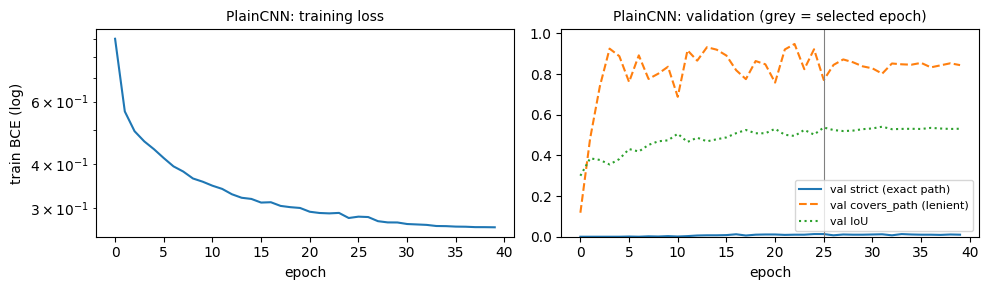

PlainCNN (seed 0), held-out test: {'strict': 0.012, 'exact': 0.012, 'iou': 0.53, 'precision': 0.544, 'recall': 0.975, 'covers_path': 0.78, 'wall_hits': 0.0, 'extra_cells': 9.926, 'missed_cells': 0.448}

strict accuracy by solution length:  RecurrentCNN vs PlainCNN
  1-3    n= 292   0.983   0.000
  4-5    n= 222   0.968   0.009
  6-7    n= 190   0.921   0.005
  8-9    n= 152   0.901   0.026
  10-12  n= 108   0.935   0.028
  13-20  n=  36   0.833   0.056


In [23]:
# ======================= 8. Train the PlainCNN baseline (seed 0) =======================
make_plain = lambda: PlainCNN(**MODEL_CFG["PlainCNN"])
print("PlainCNN params:", n_params(make_plain()), "| RecurrentCNN params:", n_params(make_rcnn()))
plain, plain_hist = train_model(make_plain, T=1, seed=0, tag="plain_cnn")
plot_history(plain_hist, "PlainCNN")
plain_test, plain_rows, plain_probs = evaluate_model(plain, ds["test"], T=1)
print("PlainCNN (seed 0), held-out test:", {k: round(v, 3) for k, v in plain_test.items()})
print("\nstrict accuracy by solution length:  RecurrentCNN vs PlainCNN")
for (lab, n, a1), (_, _, a2) in zip(accuracy_by_length(rcnn_rows, ds["test"]),
                                    accuracy_by_length(plain_rows, ds["test"])):
    print("  %-6s n=%4d   %.3f   %.3f" % (lab, n, a1, a2))

## 9) Model comparison over 3 seeds (held-out test)

Seeds 1 and 2 are trained for both models with exactly the same protocol; the table reports
mean +/- standard deviation over seeds 0-2 on the 1,000 held-out test mazes. Results and
hyperparameters are written to `week1_results/week1_metrics.json` for the Week-2 comparison.

trained RecurrentCNN seed 1 (best epoch 35, 412s)
trained RecurrentCNN seed 2 (best epoch 34, 412s)
trained PlainCNN seed 1 (best epoch 34, 125s)
trained PlainCNN seed 2 (best epoch 29, 122s)
model           params   T          strict           exact             iou       precision          recall     covers_path
--------------------------------------------------------------------------------------------------------------------------
RecurrentCNN      9989   8 0.934 +/- 0.014 0.934 +/- 0.014 0.991 +/- 0.002 0.993 +/- 0.002 0.998 +/- 0.001 0.979 +/- 0.006
PlainCNN         12259   1 0.012 +/- 0.002 0.012 +/- 0.002 0.532 +/- 0.003 0.543 +/- 0.005 0.981 +/- 0.005 0.825 +/- 0.039

per-seed test strict: {'RecurrentCNN': [0.945, 0.944, 0.914], 'PlainCNN': [0.012, 0.01, 0.015]}


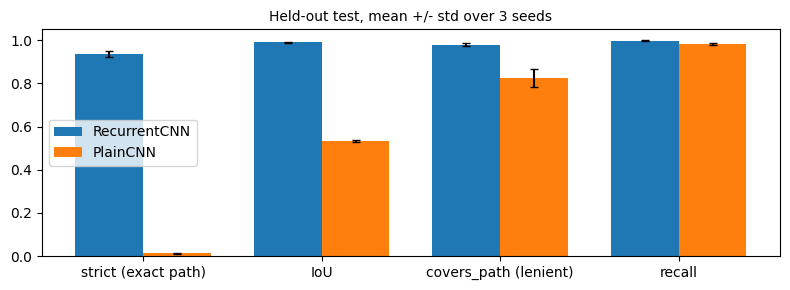

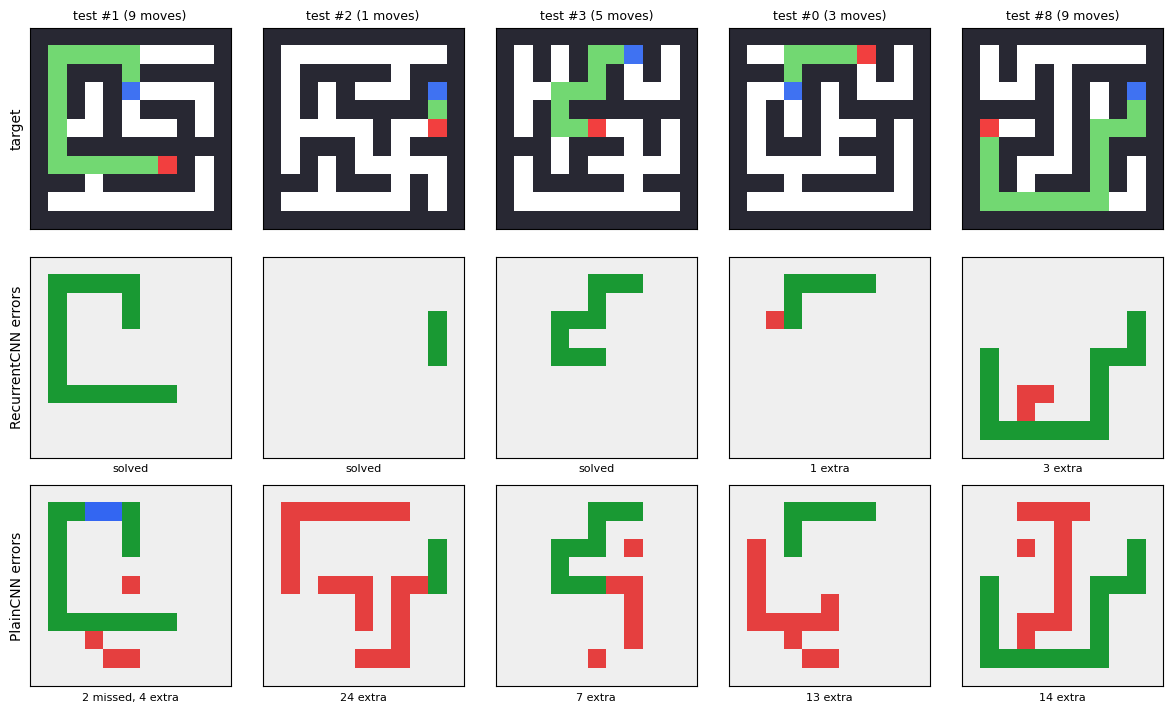

saved /content/week1_results/week1_metrics.json


In [24]:
# ======================= 9. Multi-seed comparison table + visual comparison =======================
runs = {"RecurrentCNN": {0: (rcnn, rcnn_hist)}, "PlainCNN": {0: (plain, plain_hist)}}
specs = {"RecurrentCNN": (make_rcnn, T_REC, "recurrent_cnn"), "PlainCNN": (make_plain, 1, "plain_cnn")}
for name, (mk, T, tag) in specs.items():
    for seed in HYPERPARAMS["seeds"]:
        if seed not in runs[name]:
            runs[name][seed] = train_model(mk, T=T, seed=seed, tag=tag, verbose=False)
            print("trained %s seed %d (best epoch %d, %.0fs)"
                  % (name, seed, runs[name][seed][1]["best_epoch"], runs[name][seed][1]["train_time_s"]))

METRICS = ["strict", "exact", "iou", "precision", "recall", "covers_path", "wall_hits",
           "extra_cells", "missed_cells"]
table = {}
for name, (mk, T, tag) in specs.items():
    per_seed = [evaluate_model(runs[name][s][0], ds["test"], T)[0] for s in HYPERPARAMS["seeds"]]
    table[name] = dict(params=n_params(mk()), T=T, per_seed=per_seed,
                       mean={m: float(np.mean([p[m] for p in per_seed])) for m in METRICS},
                       std={m: float(np.std([p[m] for p in per_seed])) for m in METRICS})

hdr = "%-14s %7s %3s " % ("model", "params", "T") + " ".join("%15s" % m for m in METRICS[:6])
print(hdr)
print("-" * len(hdr))
for name, t in table.items():
    print("%-14s %7d %3d " % (name, t["params"], t["T"]) +
          " ".join("%15s" % ("%.3f +/- %.3f" % (t["mean"][m], t["std"][m])) for m in METRICS[:6]))
print("\nper-seed test strict:", {n: [round(p["strict"], 3) for p in t["per_seed"]] for n, t in table.items()})

fig, ax = plt.subplots(figsize=(8, 3))
xs = np.arange(4)
for j, name in enumerate(table):
    ms = ["strict", "iou", "covers_path", "recall"]
    ax.bar(xs + 0.38 * j, [table[name]["mean"][m] for m in ms], 0.38,
           yerr=[table[name]["std"][m] for m in ms], capsize=3, label=name)
ax.set_xticks(xs + 0.19); ax.set_xticklabels(["strict (exact path)", "IoU", "covers_path (lenient)", "recall"])
ax.set_ylim(0, 1.05); ax.legend(); ax.set_title("Held-out test, mean +/- std over 3 seeds")
plt.tight_layout()
plt.show()

# ---- side-by-side visual comparison on the same test mazes (seed-0 models) ----
disagree = [k for k in range(len(ds["test"])) if rcnn_rows[k]["strict"] != plain_rows[k]["strict"]]
ks = (disagree[:3] + [k for k in range(len(ds["test"])) if k not in disagree][:2])[:5]
d = ds["test"]
fig, axes = plt.subplots(3, len(ks), figsize=(2.4 * len(ks), 7.2), squeeze=False)
for j, k in enumerate(ks):
    gt = d.y[k].numpy() > 0.5
    w, s, g = d.walls[k], d.starts[k], d.goals[k]
    axes[0, j].imshow(maze_rgb(w, s, g, gt))
    axes[0, j].set_title("test #%d (%d moves)" % (k, len(d.solutions[k])), fontsize=9)
    for i, (nm, pr, rw) in enumerate([("RecurrentCNN", rcnn_probs, rcnn_rows),
                                      ("PlainCNN", plain_probs, plain_rows)], start=1):
        axes[i, j].imshow(error_rgb(pr[k] >= 0.5, gt))
        axes[i, j].set_xlabel(failure_reason(rw[k]), fontsize=8)
    for i in range(3):
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
for i, lab in enumerate(["target", "RecurrentCNN errors", "PlainCNN errors"]):
    axes[i, 0].set_ylabel(lab)
plt.tight_layout()
plt.show()

summary = dict(
    config=CONFIG, hyperparams=HYPERPARAMS, model_cfg=MODEL_CFG,
    validation=dict(total=len(MAZES), valid={lv: len(v) for lv, v in valid.items()},
                    exact_duplicates=exact_dups, symmetry_duplicates=canon_dups),
    test_results={n: dict(params=t["params"], T=t["T"], mean=t["mean"], std=t["std"],
                          per_seed_strict=[p["strict"] for p in t["per_seed"]],
                          best_epochs=[runs[n][s][1]["best_epoch"] for s in HYPERPARAMS["seeds"]])
                  for n, t in table.items()},
)
(RESULTS / "week1_metrics.json").write_text(json.dumps(summary, indent=2))
print("saved", RESULTS / "week1_metrics.json")

## 10) Week-1 conclusions, limitations and Week-2 outlook

### 10.1 Week-1 Deliverables Summary

- **Dataset Selection (P0):** Documented **`selimaktas/maze-curriculum-dataset`** (60,000 ASCII perfect mazes across `grid_size` 5, 7, and 9 with provided move-string solutions). Inspected all three curriculum levels, grid dimensions ($11\times 11$, $15\times 15$, $19\times 19$), and move-length distributions (`5.7`, `8.9`, and `12.5` mean moves; Section 1).
- **Data Adapter (P0):** Implemented pure rule-following functions (`parse_maze`, `maze_to_channels`, `replay_solution`) and a full PyTorch `MazeDataset` + `DataLoader` pipeline without any BFS or graph search in label generation (Section 2).
- **Dataset Validation (P0):** Enforced 10 rigorous checks across all **60,000** mazes in `13.4s` — rectangular shape, endpoint validity, outer wall borders, lattice parity, a search-free union-find **perfect-maze (spanning-tree) proof**, legal move replay without wall collisions, exact termination on `E`, simple paths (no revisits), and both exact and dihedral ($D_4$ rotation/reflection) duplicate detection (`0` failures and `0` duplicates across all 60,000 samples). Asserted zero data leakage across `train` (4,000) / `val` (1,000) / `test` (1,000) splits (Section 3).
- **Strict Evaluation Metric (P0):** Replaced `v1`'s lenient subgraph-containment check with a search-free deterministic path tracer (`trace_path`, `evaluate_mask`) requiring the prediction to form **one exact, unbranched, legal S-to-G path with zero wall hits and zero extra cells**. Retained the lenient connectivity check as `covers_path` alongside `exact`, `iou`, `precision`, `recall`, `wall_hits`, `extra_cells`, and `missed_cells` (Section 4).
- **Baseline Models & 3-Seed Comparison (P0 & P1):** Trained `RecurrentCNN` ($T=8$, 9,989 params) and non-recurrent `PlainCNN` (depth 6, 12,259 params) across 3 seeds (`0, 1, 2`) with cosine learning-rate decay, gradient clipping, and best-validation checkpointing (Sections 5–9).

### 10.2 Documented First Set of Hyperparameters & Held-Out Test Results

| Hyperparameter | Value | Notes |
|---|---|---|
| Optimizer & LR | `Adam` ($\text{lr} = 10^{-3}$) | Cosine annealing schedule to $0$ over training steps |
| Gradient clipping | $\max \|\nabla\|_2 = 1.0$ | Prevents mid-training recurrent instability |
| Batch size / Epochs | `32` / `40` | Best checkpoint selected on validation `strict` accuracy |
| Loss function | `BCEWithLogitsLoss` | Weighted by training `pos_weight = 8.76` |
| Prediction threshold | `0.5` | Applied to sigmoid probabilities |
| Recurrent steps ($T$) | `8` (`RecurrentCNN`), `1` (`PlainCNN`) | Weight-shared residual loop vs. feed-forward stack |

**Held-Out Test Results (`grid_size = 5`, $n = 1{,}000$, mean $\pm$ std over 3 seeds):**

| Model | Params | $T$ | `strict` (= `exact`) | `iou` | `precision` | `recall` | `covers_path` (lenient) |
|---|---:|---:|---:|---:|---:|---:|---:|
| **`RecurrentCNN`** | 9,989 | 8 | **$0.934 \pm 0.014$** | $0.991 \pm 0.002$ | $0.993 \pm 0.002$ | $0.998 \pm 0.001$ | $0.979 \pm 0.006$ |
| **`PlainCNN`** | 12,259 | 1 | **$0.012 \pm 0.002$** | $0.532 \pm 0.003$ | $0.543 \pm 0.005$ | $0.981 \pm 0.005$ | $0.825 \pm 0.039$ |

### 10.3 Key Findings & Identified Limitations (Hand-off to Week 2)

1. **Why Strict Evaluation Matters (`strict` vs. `covers_path`):** Under `v1`'s lenient check (`covers_path`), `PlainCNN` appears to solve $82.5\%$ of test mazes—not because it finds the path, but because it over-predicts corridors ($\text{recall} = 0.981$, $\text{precision} = 0.543$, averaging $9.9$ extra false-positive cells per maze). Under true `strict` evaluation, `PlainCNN` solves only **$1.2\%$** of mazes, whereas `RecurrentCNN` ($T=8$) solves **$93.4\%$** ($94.5\%$ on seed 0).
2. **Degradation on Longer Paths at Fixed $T=8$:** On seed 0, `RecurrentCNN` achieves $98.3\%$ strict accuracy on short paths ($1\text{--}3$ moves) and $96.8\%$ on $4\text{--}5$ moves, but drops to **$83.3\%$ on long paths ($13\text{--}20$ moves, i.e., $27\text{--}41$ ASCII cells)** where 8 recurrent iterations are barely sufficient to propagate information from both endpoints and prune dead-end branches.
3. **Dominant Failure Modes:** Among the 55 failed test mazes for `RecurrentCNN` (seed 0), **zero** are wall hits (`wall_hits = 0.0`); 36 are **extra cells only (unpruned spurs/islands)**, 17 are **missed cells (1-cell gaps along long corridors)**, and 2 are wrong branches. Unpruned spurs motivate Week 2's **Coagulation–Fragmentation (CF)** model, where fragmentation ($A_2 \to 2A_1$) is designed to split false-positive dead-end clusters back into revisable monomers.
4. **Wall-Blind $3 \times 3$ Convolutions:** Standard $3 \times 3$ kernels aggregate features across 1-cell-thick ASCII walls (`#`), motivating the Week-2 P1 investigation into wall-aware updates.